# 03 · Task vectors and merges

- **Task vector** of a specialist: `tv_t = specialist_t − base`, over the 168 LoRA target matrices.
- **Merge delta**: `Δ_m = merged_m − base` for avg, task arithmetic, TIES.

Both are read from the saved bf16 folders, i.e. the exact numbers `merge.py` used.

Questions this notebook answers with the weights alone (no eval):
1. Do the three task vectors overlap or point in different directions?
2. How much of each specialist's direction does each merge carry? Compare that with RRR.

In [ ]:
import sys, json, struct
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, torch, matplotlib.pyplot as plt
from safetensors import safe_open
from src.merge.merge import LazyWeights

BASE = "Qwen/Qwen2.5-1.5B-Instruct"     # HF id (read from your HF cache) or a local folder
SEED = 42
TASKS = ["gsm8k", "logic", "code"]
METHODS = ["avg", "task_arithmetic", "ties"]
MODULES = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
SPEC = {t: ROOT / f"checkpoints/specialists/{t}/seed{SEED}" for t in TASKS}
MERGED = {m: ROOT / f"checkpoints/merged/{m}" for m in METHODS}

# fixed colours: tasks always blue/orange/aqua, methods always yellow/magenta/green
C_TASK = dict(zip(TASKS, ["#2a78d6", "#eb6834", "#1baf7a"]))
C_METHOD = dict(zip(METHODS, ["#eda100", "#e87ba4", "#008300"]))
C_MOD = dict(zip(MODULES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]))

torch.set_printoptions(precision=4, sci_mode=False, linewidth=150)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e4e0", "axes.axisbelow": True})

def sub(module):
    return "self_attn" if module in MODULES[:4] else "mlp"

def wname(layer, module):
    return f"model.layers.{layer}.{sub(module)}.{module}.weight"

base = LazyWeights(BASE)
cfg = json.loads((base.path / "config.json").read_text())
N_LAYERS = cfg["num_hidden_layers"]
print("base folder:", base.path)

/mnt/EAD854DBD854A799/IITB Course/Sem 7/CS769 (Optimisation in Machine Learning)/Project (Does RL-induced reasoning survive merging)/Does_RL-induced_reasoning_survive_merging/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 6 files: 100%|██████████| 6/6 [00:00<00:00, 614.28it/s]

base folder: /home/navya-garg/.cache/huggingface/hub/models--Qwen--Qwen2.5-0.5B-Instruct/snapshots/7ae557604adf67be50417f59c2c2f167def9a775


In [2]:
specs = [LazyWeights(SPEC[t] / "merged") for t in TASKS]
merges = [LazyWeights(MERGED[m]) for m in METHODS]
keys = [wname(l, m) for l in range(N_LAYERS) for m in MODULES]
T, K = len(TASKS), len(METHODS)

G = np.zeros((T, T))                              # <tv_i, tv_j>
P = np.zeros((K, T))                              # <Δ_m, tv_t>
DN = np.zeros(K)                                  # |Δ_m|^2
G_layer = np.zeros((N_LAYERS, T, T))
DN_layer = np.zeros((N_LAYERS, K))
G_mod = np.zeros((len(MODULES), T, T))
nz_tv, nz_d = np.zeros(T), np.zeros(K)
all3 = all3_agree = 0
total = 0
for k in keys:
    l, j = int(k.split(".")[2]), MODULES.index(k.split(".")[-2])
    b = base.get(k).float()
    tv = torch.stack([s.get(k).float() - b for s in specs]).reshape(T, -1).double()
    d = torch.stack([m.get(k).float() - b for m in merges]).reshape(K, -1).double()
    g = (tv @ tv.T).numpy()
    G += g; G_layer[l] += g; G_mod[j] += g
    P += (d @ tv.T).numpy()
    dn = (d * d).sum(1).numpy(); DN += dn; DN_layer[l] += dn
    nz_tv += (tv != 0).sum(1).numpy(); nz_d += (d != 0).sum(1).numpy()
    sg = torch.sign(tv); nz = (sg != 0).all(0)
    all3 += nz.sum().item(); all3_agree += (nz & (sg[0] == sg[1]) & (sg[1] == sg[2])).sum().item()
    total += tv.shape[1]
print(f"{len(keys)} matrices, {total / 1e6:.1f}M weights scanned")

168 matrices, 357.8M weights scanned


## 1. How big is each vector, and how much of it is non-zero?

Zero entries in a task vector are weights the specialist did not change (or bf16 rounded away).
TIES keeps only the top 20% per specialist, so its delta should be sparser.

In [3]:
for i, t in enumerate(TASKS):
    print(f"tv  {t:<16} |tv| = {np.sqrt(G[i, i]):8.4f}   non-zero {nz_tv[i] / total:6.1%}")
for i, m in enumerate(METHODS):
    print(f"Δ   {m:<16} |Δ|  = {np.sqrt(DN[i]):8.4f}   non-zero {nz_d[i] / total:6.1%}")

tv  gsm8k            |tv| =   0.7775   non-zero  40.0%
tv  logic            |tv| =   0.7544   non-zero  39.1%
tv  code             |tv| =   0.7921   non-zero  40.5%
Δ   avg              |Δ|  =   0.4534   non-zero  28.2%
Δ   task_arithmetic  |Δ|  =   1.3748   non-zero  53.7%
Δ   ties             |Δ|  =   1.0642   non-zero  44.8%


## 2. Do the task vectors overlap?

Cosine similarity: 1 = same direction, 0 = unrelated (orthogonal), −1 = opposite.
Two random vectors this large have cosine ≈ 0.
The Sparsity Curse paper reports RL task vectors are nearly orthogonal. This checks it on ours.

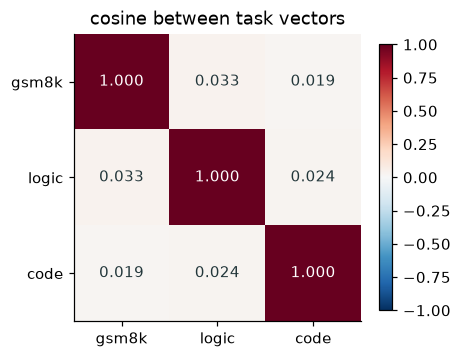

sign agreement where all 3 changed a weight: 27.2%  (random = 25%)


In [4]:
cos = G / np.sqrt(np.outer(np.diag(G), np.diag(G)))
fig, ax = plt.subplots(figsize=(4.2, 3.6))
im = ax.imshow(cos, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(T), TASKS); ax.set_yticks(range(T), TASKS); ax.grid(False)
for i in range(T):
    for j in range(T):
        ax.text(j, i, f"{cos[i, j]:.3f}", ha="center", va="center", fontsize=10,
                color="white" if abs(cos[i, j]) > 0.6 else "#23373b")
plt.colorbar(im, shrink=0.8); ax.set_title("cosine between task vectors")
plt.tight_layout(); plt.show()
print(f"sign agreement where all 3 changed a weight: {all3_agree / max(all3, 1):.1%}  (random = 25%)")

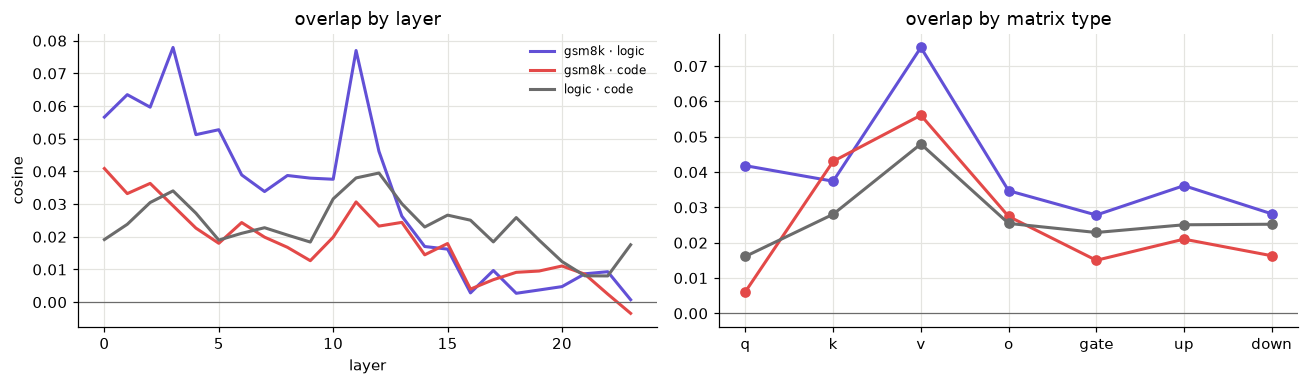

In [5]:
pairs = [(0, 1), (0, 2), (1, 2)]
C_PAIR = ["#6250d6", "#e34948", "#6b6b6b"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for (i, j), c in zip(pairs, C_PAIR):
    lc = G_layer[:, i, j] / np.sqrt(G_layer[:, i, i] * G_layer[:, j, j])
    mc = G_mod[:, i, j] / np.sqrt(G_mod[:, i, i] * G_mod[:, j, j])
    axes[0].plot(range(N_LAYERS), lc, color=c, lw=2, label=f"{TASKS[i]} · {TASKS[j]}")
    axes[1].plot(range(len(MODULES)), mc, color=c, lw=2, marker="o", ms=6)
axes[0].set_xlabel("layer"); axes[0].set_ylabel("cosine")
axes[0].xaxis.get_major_locator().set_params(integer=True); axes[0].legend(frameon=False, fontsize=8)
axes[1].set_xticks(range(len(MODULES)), [m.replace("_proj", "") for m in MODULES])
axes[0].set_title("overlap by layer"); axes[1].set_title("overlap by matrix type")
for ax in axes: ax.axhline(0, color="#6b6b6b", lw=0.8)
plt.tight_layout(); plt.show()

## 3. How much of each specialist survives in each merge (weight space)

Project the merge delta onto each task vector:

**share_t = ⟨Δ_m, tv_t⟩ / |tv_t|²**

- 1 = the merge moved fully along specialist t's direction
- 1/3 = what plain averaging gives when the task vectors are orthogonal
- This is the weight-space twin of RRR. RRR measures accuracy; this measures direction.

If share and RRR disagree, the weights are not the whole story (e.g. TIES drops 80% of entries but may keep the important ones).

In [6]:
share = P / np.diag(G)[None, :]

rrr = {}
found = sorted(ROOT.glob("results/**/rrr.csv"))
if found:
    import csv
    for row in csv.DictReader(open(found[0])):
        rrr[row["label"].replace("merge-", "")] = {t: row.get(t) for t in TASKS}
    print("RRR from", found[0].relative_to(ROOT))
else:   # 3 Oct warm-up numbers
    rrr = {"avg": {"logic": 0.29, "code": 0.63}, "task_arithmetic": {"logic": 0.97, "code": 0.85},
           "ties": {"logic": 1.32, "code": 1.11}}
    print("rrr.csv not found; using the 3 Oct warm-up RRR")

def fmt(x):
    try: return f"{float(x):6.2f}"
    except (TypeError, ValueError): return "   n/a"

print(f"\n{'method':<16}{'task':<8}{'share':>8}{'RRR':>8}")
for i, m in enumerate(METHODS):
    for j, t in enumerate(TASKS):
        print(f"{m:<16}{t:<8}{share[i, j]:8.2f}{fmt(rrr.get(m, {}).get(t))}")

RRR from results/rrr.csv

method          task       share     RRR
avg             gsm8k       0.28   n/a
avg             logic       0.29  0.29
avg             code        0.27  0.63
task_arithmetic gsm8k       1.05   n/a
task_arithmetic logic       1.06  0.97
task_arithmetic code        1.04  0.85
ties            gsm8k       0.72   n/a
ties            logic       0.71  1.32
ties            code        0.73  1.11


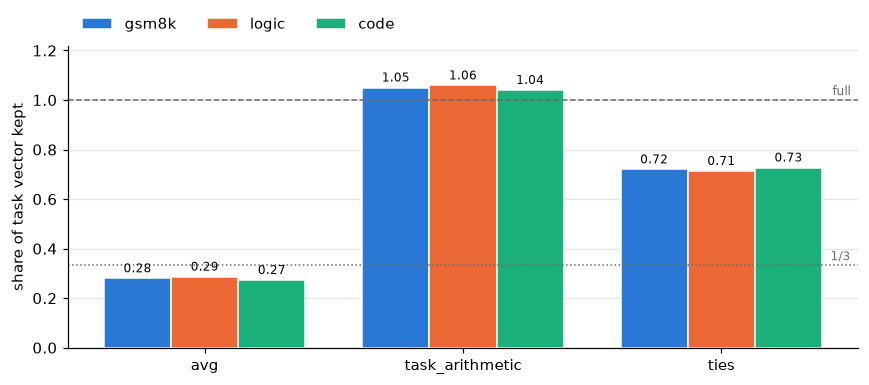

In [7]:
x = np.arange(K); w = 0.26
fig, ax = plt.subplots(figsize=(8, 3.6))
for j, t in enumerate(TASKS):
    bars = ax.bar(x + (j - 1) * w, share[:, j], w, color=C_TASK[t], label=t, edgecolor="white", linewidth=1)
    ax.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
ax.axhline(1, color="#6b6b6b", ls="--", lw=1); ax.text(K - 0.5, 1.02, "full", color="#6b6b6b", ha="right", fontsize=8)
ax.axhline(1 / 3, color="#6b6b6b", ls=":", lw=1); ax.text(K - 0.5, 1 / 3 + 0.02, "1/3", color="#6b6b6b", ha="right", fontsize=8)
ax.set_xticks(x, METHODS); ax.set_ylabel("share of task vector kept")
ax.legend(frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0)); ax.grid(axis="x", visible=False)
ax.set_ylim(0, max(1.15, share.max() * 1.15))
plt.tight_layout(); plt.show()

## 4. Size of each merge, layer by layer

Norm of Δ per layer for each merge, next to the specialists' |tv|.

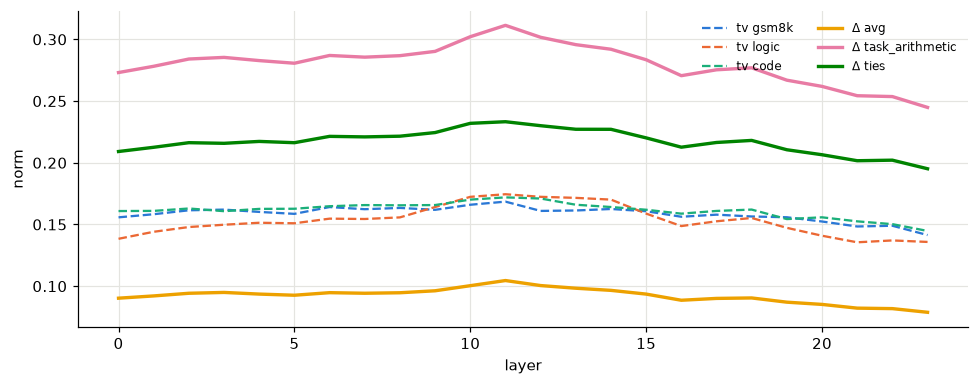

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, t in enumerate(TASKS):
    ax.plot(range(N_LAYERS), np.sqrt(G_layer[:, i, i]), color=C_TASK[t], lw=1.5, ls="--", label=f"tv {t}")
for i, m in enumerate(METHODS):
    ax.plot(range(N_LAYERS), np.sqrt(DN_layer[:, i]), color=C_METHOD[m], lw=2.2, label=f"Δ {m}")
ax.set_xlabel("layer"); ax.set_ylabel("norm")
ax.legend(frameon=False, ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

## 5. Real numbers, side by side

For one matrix: the 8 weights the specialists changed most, plus 4 random ones.
Every column is a change from base, except `base`.
Check by hand: `avg` = mean of the three tv columns; `task_arithmetic` = their sum (λ = 1); TIES zeroes small ones and drops minority signs.

In [9]:
import pandas as pd
L, M = N_LAYERS // 2, "down_proj"
k = wname(L, M)
b = base.get(k).float().flatten()
tv = torch.stack([s.get(k).float().flatten() - b for s in specs])
d = torch.stack([m.get(k).float().flatten() - b for m in merges])
top = tv.abs().sum(0).topk(8).indices
rnd = torch.randperm(b.numel(), generator=torch.Generator().manual_seed(0))[:4]
idx = torch.cat([top, rnd])
shape = base.get(k).shape
df = pd.DataFrame({"(row, col)": [tuple(divmod(int(i), shape[1])) for i in idx],
                   "base": b[idx].numpy(),
                   **{f"tv {t}": tv[i, idx].numpy() for i, t in enumerate(TASKS)},
                   **{f"Δ {m}": d[i, idx].numpy() for i, m in enumerate(METHODS)}})
df.index = ["top"] * 8 + ["random"] * 4
print(k)
df.style.format({c: "{:+.6f}" for c in df.columns[1:]})

model.layers.12.mlp.down_proj.weight


,"(row, col)",base,tv gsm8k,tv logic,tv code,Δ avg,Δ task_arithmetic,Δ ties
top,"(92, 2141)",-0.031494,-0.000244,-0.000244,+0.000000,-0.000244,-0.000488,-0.000244
top,"(62, 1583)",+0.020996,+0.000122,+0.000122,+0.000122,+0.000122,+0.000366,+0.000122
top,"(62, 586)",-0.019165,-0.000122,-0.000122,-0.000122,-0.000122,-0.000366,-0.000122
top,"(62, 883)",-0.031250,+0.000122,+0.000122,+0.000122,+0.000122,+0.000366,+0.000122
top,"(62, 704)",-0.019043,-0.000122,-0.000122,-0.000122,-0.000122,-0.000366,-0.000122
top,"(62, 162)",-0.026855,-0.000122,-0.000122,-0.000122,-0.000122,-0.000366,-0.000122
top,"(62, 1667)",-0.021240,-0.000122,-0.000122,-0.000122,-0.000122,-0.000366,-0.000122
top,"(62, 261)",+0.021606,+0.000122,+0.000122,+0.000122,+0.000122,+0.000366,+0.000122
random,"(768, 2732)",+0.008911,+0.000000,+0.000000,+0.000000,+0.000000,+0.000000,+0.000000
random,"(224, 3192)",-0.005890,+0.000000,+0.000000,+0.000000,+0.000000,+0.000000,+0.000000
